In [ ]:

import os
import random
import numpy as np
import tensorflow as tf

# ---- Reproducibility ----
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {tf.keras.__version__}")

# ---- GPU Check ----
gpus = tf.config.list_physical_devices('GPU')
print(f"\nNum GPUs detected: {len(gpus)}")
for gpu in gpus:
    print(" -", gpu)

if len(gpus) == 0:
    raise RuntimeError(
        "No GPU detected! Go to Notebook Settings (right sidebar) -> "
        "Accelerator -> select 'GPU T4 x2' -> Save, then restart the session."
    )

# ---- Prevent full memory pre-allocation (avoids early OOM crashes) ----
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print("Memory growth setting failed (session may already be running):", e)

# ---- Mixed precision (float16 compute, float32 variables) ----
# Gives a real speedup on T4's Tensor Cores. Loss scaling is automatic.
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
policy = mixed_precision.global_policy()
print(f"\nMixed precision compute dtype: {policy.compute_dtype}")
print(f"Mixed precision variable dtype: {policy.variable_dtype}")

# ---- Distribution strategy: use both T4s if available ----
if len(gpus) > 1:
    strategy = tf.distribute.MirroredStrategy()
else:
    strategy = tf.distribute.get_strategy()
print(f"\nNumber of devices in strategy: {strategy.num_replicas_in_sync}")

# ---- Dataset path verification ----
DATASET_DIR = "/kaggle/input/datasets/mohammadzaimullah/figshare-dataset"

print(f"\nChecking dataset path: {DATASET_DIR}")
if not os.path.exists(DATASET_DIR):
    raise FileNotFoundError(
        f"Path does not exist: {DATASET_DIR}\n"
        f"Listing /kaggle/input to help locate the correct path:"
    )

print("\nTop-level contents of dataset directory:")
for item in sorted(os.listdir(DATASET_DIR)):
    full_path = os.path.join(DATASET_DIR, item)
    if os.path.isdir(full_path):
        try:
            n_items = len(os.listdir(full_path))
        except PermissionError:
            n_items = "?"
        print(f"  [DIR]  {item}  ({n_items} items)")
    else:
        size_kb = os.path.getsize(full_path) / 1024
        print(f"  [FILE] {item}  ({size_kb:.1f} KB)")

# If it's nested one level deeper, peek into the first subdirectory too
top_items = sorted(os.listdir(DATASET_DIR))
first_dir = next((os.path.join(DATASET_DIR, i) for i in top_items
                   if os.path.isdir(os.path.join(DATASET_DIR, i))), None)
if first_dir:
    print(f"\nPeeking inside first subdirectory: {first_dir}")
    inner_items = sorted(os.listdir(first_dir))[:10]
    for item in inner_items:
        print("   -", item)
    print(f"   ... ({len(os.listdir(first_dir))} total items in this folder)")

print("\n✅ Step 1 complete if no errors were raised above.")

2026-06-22 08:55:32.692789: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782118533.109903      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782118533.236560      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782118534.272765      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782118534.272814      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782118534.272817      58 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
Keras version: 3.13.2

Num GPUs detected: 2
 - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
 - PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

Mixed precision compute dtype: float16
Mixed precision variable dtype: float32
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')

Number of devices in strategy: 2

Checking dataset path: /kaggle/input/datasets/mohammadzaimullah/figshare-dataset

Top-level contents of dataset directory:
  [DIR]  brainTumorDataPublic_1-766  (766 items)
  [DIR]  brainTumorDataPublic_1533-2298  (766 items)
  [DIR]  brainTumorDataPublic_2299-3064  (766 items)
  [DIR]  brainTumorDataPublic_767-1532  (766 items)

Peeking inside first subdirectory: /kaggle/input/datasets/mohammadzaimullah/figshare-dataset/brainTumorDataPublic_1-766
   - 1.mat
   - 10.mat
   - 100.mat
   - 101.mat
   - 102.mat
   - 103.mat
   

I0000 00:00:1782118556.728180      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782118556.733996      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [ ]:

import h5py
import numpy as np
import glob
import re
from collections import Counter
import pickle
import time

SUBDIRS = [
    "brainTumorDataPublic_1-766",
    "brainTumorDataPublic_767-1532",
    "brainTumorDataPublic_1533-2298",
    "brainTumorDataPublic_2299-3064",
]

LABEL_MAP = {1: "meningioma", 2: "glioma", 3: "pituitary"}

# ---- Collect all file paths, sorted numerically by file index ----
all_paths = []
for sub in SUBDIRS:
    folder = os.path.join(DATASET_DIR, sub)
    paths = glob.glob(os.path.join(folder, "*.mat"))
    all_paths.extend(paths)

def file_index(p):
    return int(re.search(r"(\d+)\.mat$", os.path.basename(p)).group(1))

all_paths = sorted(all_paths, key=file_index)
print(f"Total .mat files found: {len(all_paths)}")
assert len(all_paths) == 3064, f"Expected 3064 files, found {len(all_paths)}"

# ---- Parse each file ----
images = []          # list of 2D numpy arrays (variable size)
labels = []
pids = []
shapes = []
dtypes = []
minmax = []
failed = []

t0 = time.time()
for i, path in enumerate(all_paths):
    try:
        with h5py.File(path, 'r') as f:
            cj = f['cjdata']

            label = int(np.array(cj['label']).item())

            img = np.array(cj['image']).T  # transpose: HDF5/MATLAB storage is transposed
            img = img.astype(np.float32)

            pid_raw = np.array(cj['PID']).flatten()
            try:
                pid = ''.join(chr(int(c)) for c in pid_raw)
            except Exception:
                pid = str(pid_raw.tobytes())

            images.append(img)
            labels.append(label)
            pids.append(pid)
            shapes.append(img.shape)
            dtypes.append(img.dtype)
            minmax.append((img.min(), img.max()))

    except Exception as e:
        failed.append((path, str(e)))

    if (i + 1) % 500 == 0:
        print(f"  parsed {i+1}/{len(all_paths)}  ({time.time()-t0:.1f}s elapsed)")

print(f"\nDone parsing in {time.time()-t0:.1f}s")
print(f"Successfully parsed: {len(images)}")
print(f"Failed: {len(failed)}")
if failed:
    print("First few failures:")
    for p, e in failed[:5]:
        print(" -", p, "->", e)

# ---- Class distribution ----
label_counts = Counter(labels)
print("\nClass distribution:")
for lbl, name in LABEL_MAP.items():
    print(f"  {lbl} ({name}): {label_counts.get(lbl, 0)}")

# ---- Image size / dtype variability ----
unique_shapes = Counter(shapes)
print(f"\nUnique image shapes found: {len(unique_shapes)}")
for shp, cnt in sorted(unique_shapes.items(), key=lambda x: -x[1])[:10]:
    print(f"  {shp}: {cnt} images")

mins = [m[0] for m in minmax]
maxs = [m[1] for m in minmax]
print(f"\nPixel value range across dataset: min={min(mins):.1f}, max={max(maxs):.1f}")

# ---- Patient ID analysis (critical for fold strategy) ----
unique_pids = set(pids)
print(f"\nUnique patients (PIDs): {len(unique_pids)}")
print(f"Total images: {len(pids)}")
print(f"Avg images per patient: {len(pids)/len(unique_pids):.2f}")

# images-per-patient distribution
pid_img_counts = Counter(pids)
print("Images-per-patient distribution (top 10 most frequent counts):")
for cnt, n_patients in Counter(pid_img_counts.values()).most_common(10):
    print(f"  {cnt} image(s) -> {n_patients} patients")

# patients per class + check if any patient appears under multiple labels
pid_to_labels = {}
for p, l in zip(pids, labels):
    pid_to_labels.setdefault(p, set()).add(l)
multi_label_patients = {p: l for p, l in pid_to_labels.items() if len(l) > 1}
print(f"\nPatients with images in >1 class (should be 0): {len(multi_label_patients)}")

# ---- Cache raw parsed data to disk (avoid re-parsing if kernel restarts) ----
cache = {
    "images": images,
    "labels": labels,
    "pids": pids,
    "paths": all_paths,
}
with open("/kaggle/working/figshare_raw_cache.pkl", "wb") as f:
    pickle.dump(cache, f)
print("\n✅ Step 2 complete. Raw data cached to /kaggle/working/figshare_raw_cache.pkl")

Total .mat files found: 3064
  parsed 500/3064  (11.6s elapsed)
  parsed 1000/3064  (23.5s elapsed)
  parsed 1500/3064  (35.0s elapsed)
  parsed 2000/3064  (46.6s elapsed)
  parsed 2500/3064  (58.2s elapsed)
  parsed 3000/3064  (70.9s elapsed)

Done parsing in 72.4s
Successfully parsed: 3064
Failed: 0

Class distribution:
  1 (meningioma): 708
  2 (glioma): 1426
  3 (pituitary): 930

Unique image shapes found: 2
  (512, 512): 3049 images
  (256, 256): 15 images

Pixel value range across dataset: min=0.0, max=12728.0

Unique patients (PIDs): 233
Total images: 3064
Avg images per patient: 13.15
Images-per-patient distribution (top 10 most frequent counts):
  15 image(s) -> 20 patients
  12 image(s) -> 14 patients
  18 image(s) -> 12 patients
  4 image(s) -> 12 patients
  17 image(s) -> 11 patients
  13 image(s) -> 11 patients
  3 image(s) -> 11 patients
  10 image(s) -> 11 patients
  6 image(s) -> 10 patients
  19 image(s) -> 10 patients

Patients with images in >1 class (should be 0): 0

Normalizing + resizing all images...
  processed 1000/3064  (7.0s elapsed)
  processed 2000/3064  (13.7s elapsed)
  processed 3000/3064  (19.7s elapsed)
Done in 20.1s
X_resized shape: (3064, 224, 224, 3)
Value range before ResNet preprocess: min=0.00, max=255.00
After preprocess_input: min=-123.68, max=151.06

y_encoded shape: (3064,)
Class distribution: Counter({1: 1426, 2: 930, 0: 708})


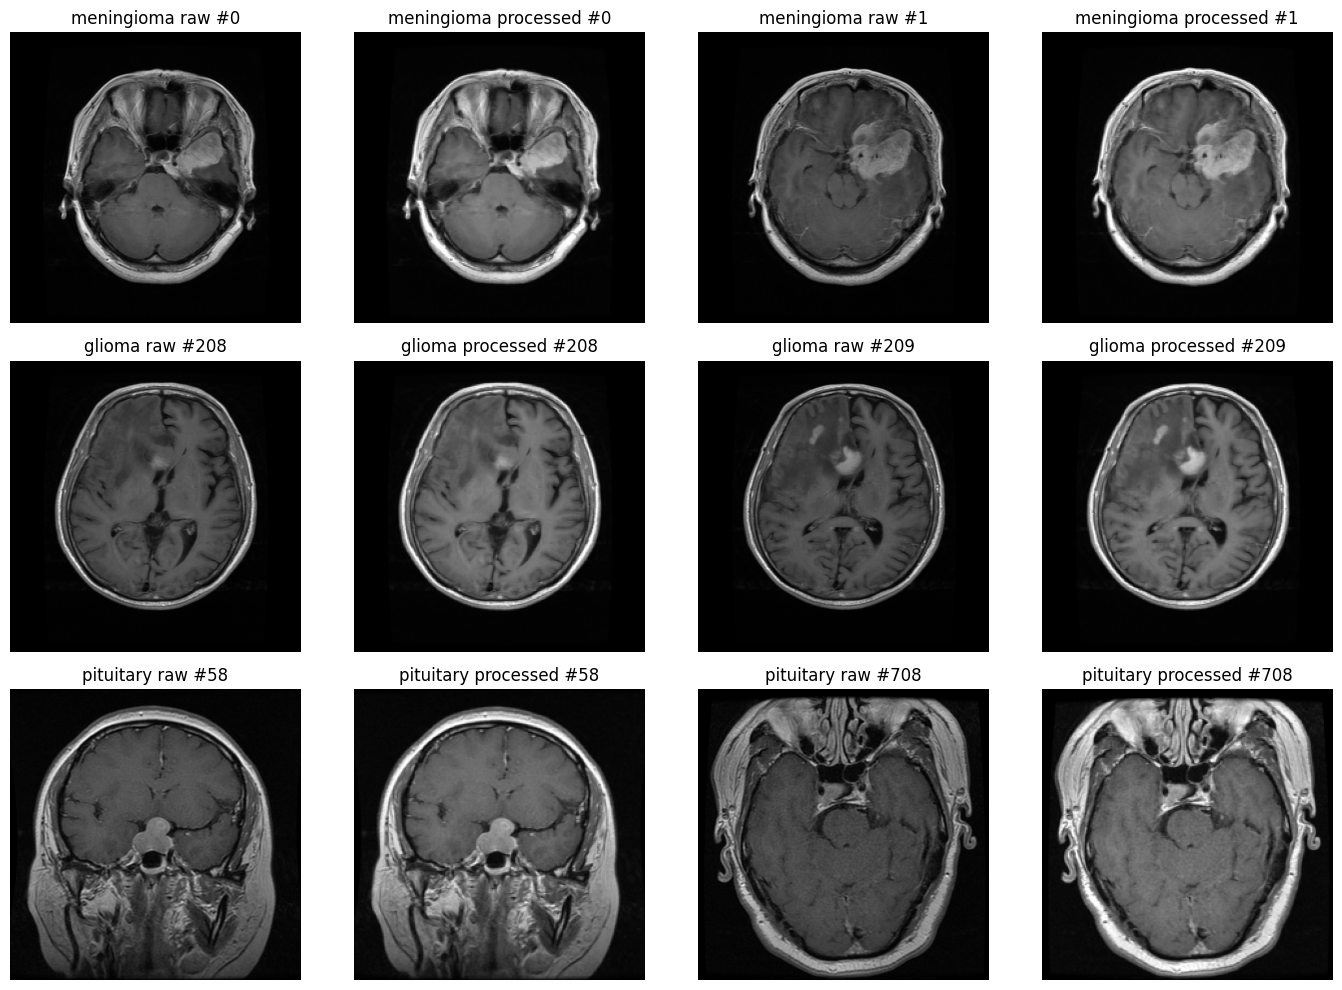

Saved sanity check to /kaggle/working/preprocessing_sanity_check.png

✅ Step 3 complete. Saved X_preprocessed.npy (1.84 GB), y_encoded.npy, pids.pkl


In [3]:
# ============================================================
# STEP 3: Preprocessing - resize, normalize, channel conversion
# ============================================================
import cv2
import time
import pickle
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from tensorflow.keras.applications.resnet50 import preprocess_input

TARGET_SIZE = 224

def normalize_image(img, low_pct=0.5, high_pct=99.5):
    """Percentile-clip then min-max normalize a single-channel image to [0, 255]."""
    lo = np.percentile(img, low_pct)
    hi = np.percentile(img, high_pct)
    if hi <= lo:
        hi, lo = img.max(), img.min()
    img = np.clip(img, lo, hi)
    img = (img - lo) / (hi - lo + 1e-8)
    return (img * 255.0).astype(np.float32)

print("Normalizing + resizing all images...")
t0 = time.time()

X_resized = np.zeros((len(images), TARGET_SIZE, TARGET_SIZE, 3), dtype=np.float32)

for i, img in enumerate(images):
    norm = normalize_image(img)
    resized = cv2.resize(norm, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_AREA)
    X_resized[i] = np.stack([resized, resized, resized], axis=-1)
    if (i + 1) % 1000 == 0:
        print(f"  processed {i+1}/{len(images)}  ({time.time()-t0:.1f}s elapsed)")

print(f"Done in {time.time()-t0:.1f}s")
print(f"X_resized shape: {X_resized.shape}")
print(f"Value range before ResNet preprocess: min={X_resized.min():.2f}, max={X_resized.max():.2f}")

# ---- ResNet50 ImageNet preprocessing (mean subtraction) ----
X_preprocessed = preprocess_input(X_resized.copy())
print(f"After preprocess_input: min={X_preprocessed.min():.2f}, max={X_preprocessed.max():.2f}")

# ---- Label encoding ----
LABEL_TO_IDX = {1: 0, 2: 1, 3: 2}  # meningioma->0, glioma->1, pituitary->2
IDX_TO_LABEL_NAME = {0: "meningioma", 1: "glioma", 2: "pituitary"}
y_encoded = np.array([LABEL_TO_IDX[l] for l in labels], dtype=np.int32)

print(f"\ny_encoded shape: {y_encoded.shape}")
print(f"Class distribution: {Counter(y_encoded.tolist())}")

# ---- Sanity check visualization: raw vs processed, 2 samples per class ----
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for cls_idx in range(3):
    idxs = np.where(y_encoded == cls_idx)[0][:2]
    for j, idx in enumerate(idxs):
        axes[cls_idx, j*2].imshow(images[idx], cmap='gray')
        axes[cls_idx, j*2].set_title(f"{IDX_TO_LABEL_NAME[cls_idx]} raw #{idx}")
        axes[cls_idx, j*2].axis('off')

        axes[cls_idx, j*2+1].imshow(X_resized[idx].astype(np.uint8))
        axes[cls_idx, j*2+1].set_title(f"{IDX_TO_LABEL_NAME[cls_idx]} processed #{idx}")
        axes[cls_idx, j*2+1].axis('off')

plt.tight_layout()
plt.savefig("/kaggle/working/preprocessing_sanity_check.png", dpi=100)
plt.show()
print("Saved sanity check to /kaggle/working/preprocessing_sanity_check.png")

# ---- Save preprocessed arrays for reuse in later steps ----
np.save("/kaggle/working/X_preprocessed.npy", X_preprocessed)
np.save("/kaggle/working/y_encoded.npy", y_encoded)
with open("/kaggle/working/pids.pkl", "wb") as f:
    pickle.dump(pids, f)

print(f"\n✅ Step 3 complete. Saved X_preprocessed.npy ({X_preprocessed.nbytes/1e9:.2f} GB), y_encoded.npy, pids.pkl")

In [4]:
# ============================================================
# STEP 4: Stratified 10-Fold split + tf.data pipeline
# ============================================================
from sklearn.model_selection import StratifiedKFold
import tensorflow as tf
import pickle
from collections import Counter

N_FOLDS = 10
BATCH_SIZE = 16

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_indices = list(skf.split(X_preprocessed, y_encoded))

print(f"Created {len(fold_indices)} folds\n")
for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    train_dist = dict(Counter(y_encoded[train_idx].tolist()))
    val_dist = dict(Counter(y_encoded[val_idx].tolist()))
    print(f"Fold {fold_i}: train={len(train_idx):4d} dist={train_dist}  |  val={len(val_idx):4d} dist={val_dist}")

with open("/kaggle/working/fold_indices.pkl", "wb") as f:
    pickle.dump(fold_indices, f)
print("\nSaved fold_indices.pkl")

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

def make_dataset(X, y, batch_size, training=True):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(
            lambda xb, yb: (tf.cast(data_augmentation(xb, training=True), tf.float32), yb),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Sanity check on fold 0
train_idx, val_idx = fold_indices[0]
X_train, y_train = X_preprocessed[train_idx], y_encoded[train_idx]
X_val, y_val = X_preprocessed[val_idx], y_encoded[val_idx]
train_ds = make_dataset(X_train, y_train, BATCH_SIZE, training=True)
val_ds = make_dataset(X_val, y_val, BATCH_SIZE, training=False)

for xb, yb in train_ds.take(1):
    print(f"Train batch: x={xb.shape}, dtype={xb.dtype}")
for xb, yb in val_ds.take(1):
    print(f"Val batch:   x={xb.shape}, dtype={xb.dtype}")

print("\n✅ Step 4 complete.")

Created 10 folds

Fold 0: train=2757 dist={0: 637, 2: 837, 1: 1283}  |  val= 307 dist={0: 71, 2: 93, 1: 143}
Fold 1: train=2757 dist={0: 637, 1: 1283, 2: 837}  |  val= 307 dist={0: 71, 2: 93, 1: 143}
Fold 2: train=2757 dist={0: 637, 2: 837, 1: 1283}  |  val= 307 dist={0: 71, 1: 143, 2: 93}
Fold 3: train=2757 dist={0: 637, 2: 837, 1: 1283}  |  val= 307 dist={0: 71, 1: 143, 2: 93}
Fold 4: train=2758 dist={0: 637, 2: 837, 1: 1284}  |  val= 306 dist={0: 71, 1: 142, 2: 93}
Fold 5: train=2758 dist={0: 637, 2: 837, 1: 1284}  |  val= 306 dist={0: 71, 2: 93, 1: 142}
Fold 6: train=2758 dist={0: 637, 2: 837, 1: 1284}  |  val= 306 dist={0: 71, 2: 93, 1: 142}
Fold 7: train=2758 dist={0: 637, 2: 837, 1: 1284}  |  val= 306 dist={0: 71, 1: 142, 2: 93}
Fold 8: train=2758 dist={0: 638, 2: 837, 1: 1283}  |  val= 306 dist={0: 70, 2: 93, 1: 143}
Fold 9: train=2758 dist={0: 638, 2: 837, 1: 1283}  |  val= 306 dist={0: 70, 1: 143, 2: 93}

Saved fold_indices.pkl
Train batch: x=(16, 224, 224, 3), dtype=<dtype: 

In [5]:
# ============================================================
# STEP 5: Model architecture, LR schedule, optimizer, callbacks
# ============================================================
import os, json

CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

NUM_CLASSES = 3
GLOBAL_BATCH_SIZE = BATCH_SIZE
TOTAL_EPOCHS = 30
WARMUP_EPOCHS = 3
PEAK_LR = 1e-3
MIN_LR_ALPHA = 0.01
WEIGHT_DECAY = 1e-4

def build_resnet_dual_output(input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    inputs = tf.keras.Input(shape=input_shape, name="input_image")
    backbone = tf.keras.applications.ResNet50(
        weights="imagenet", include_top=False, input_tensor=inputs, pooling=None
    )
    backbone.trainable = True
    n_frozen_bn = 0
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
            n_frozen_bn += 1
    feat_map = backbone.output
    embedding = tf.keras.layers.GlobalAveragePooling2D(name="embedding")(feat_map)
    x = tf.keras.layers.Dropout(0.3)(embedding)
    logits = tf.keras.layers.Dense(num_classes, dtype='float32', name="logits")(x)
    model = tf.keras.Model(inputs=inputs, outputs=[logits, embedding], name="resnet50_dual_output")
    return model, n_frozen_bn


class AdversarialNSLModel(tf.keras.Model):
    def __init__(self, base_model, epsilon=2.0, lambda_adv=0.2, lambda_emb=0.1,
                 global_batch_size=16, **kwargs):
        super().__init__(**kwargs)
        self.base_model = base_model
        self.epsilon = epsilon
        self.lambda_adv = lambda_adv
        self.lambda_emb = lambda_emb
        self.global_batch_size = global_batch_size
        self.cce = tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True, reduction=tf.keras.losses.Reduction.NONE
        )
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.acc_tracker = tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
        self.adv_acc_tracker = tf.keras.metrics.SparseCategoricalAccuracy(name="adv_accuracy")

    def call(self, inputs, training=False):
        return self.base_model(inputs, training=training)

    def _avg(self, per_example_loss):
        return tf.nn.compute_average_loss(per_example_loss, global_batch_size=self.global_batch_size)

    def train_step(self, data):
        x, y = data

        with tf.GradientTape() as tape_fgsm:
            tape_fgsm.watch(x)
            logits_tmp, _ = self.base_model(x, training=True)
            pe_loss_tmp = self.cce(y, logits_tmp)
            local_loss_for_grad = tf.reduce_mean(pe_loss_tmp)
        grad_x = tape_fgsm.gradient(local_loss_for_grad, x)
        perturbation = self.epsilon * tf.sign(grad_x)
        x_adv = tf.stop_gradient(x + perturbation)

        with tf.GradientTape() as tape:
            logits_clean, emb_clean = self.base_model(x, training=True)
            logits_adv, emb_adv = self.base_model(x_adv, training=True)

            pe_loss_clean = self.cce(y, logits_clean)
            pe_loss_adv = self.cce(y, logits_adv)
            loss_clean = self._avg(pe_loss_clean)
            loss_adv = self._avg(pe_loss_adv)

            emb_clean_norm = tf.nn.l2_normalize(tf.cast(emb_clean, tf.float32), axis=-1)
            emb_adv_norm = tf.nn.l2_normalize(tf.cast(emb_adv, tf.float32), axis=-1)
            pe_emb_reg = tf.reduce_sum(tf.square(emb_clean_norm - emb_adv_norm), axis=-1)
            emb_reg = self._avg(pe_emb_reg)

            total_loss = loss_clean + self.lambda_adv * loss_adv + self.lambda_emb * emb_reg
            if self.base_model.losses:
                total_loss += tf.add_n(self.base_model.losses)

            scaled_loss = self.optimizer.scale_loss(total_loss)

        gradients = tape.gradient(scaled_loss, self.base_model.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.base_model.trainable_variables))

        self.loss_tracker.update_state(total_loss)
        self.acc_tracker.update_state(y, logits_clean)
        self.adv_acc_tracker.update_state(y, logits_adv)
        return {"loss": self.loss_tracker.result(), "accuracy": self.acc_tracker.result(),
                "adv_accuracy": self.adv_acc_tracker.result()}

    def test_step(self, data):
        x, y = data
        logits, emb = self.base_model(x, training=False)
        pe_loss = self.cce(y, logits)
        loss = self._avg(pe_loss)
        self.loss_tracker.update_state(loss)
        self.acc_tracker.update_state(y, logits)
        return {"loss": self.loss_tracker.result(), "accuracy": self.acc_tracker.result()}

    @property
    def metrics(self):
        return [self.loss_tracker, self.acc_tracker, self.adv_acc_tracker]


def build_lr_schedule(steps_per_epoch, total_epochs=TOTAL_EPOCHS, warmup_epochs=WARMUP_EPOCHS):
    warmup_steps = steps_per_epoch * warmup_epochs
    decay_steps = steps_per_epoch * (total_epochs - warmup_epochs)
    return tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=PEAK_LR * 0.01, decay_steps=decay_steps,
        alpha=MIN_LR_ALPHA, warmup_target=PEAK_LR, warmup_steps=warmup_steps,
    )

def build_optimizer(lr_schedule):
    return tf.keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=WEIGHT_DECAY,
                                       beta_1=0.9, beta_2=0.999)

def build_callbacks(fold_i):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=10,
                                           restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(filepath=ckpt_path, monitor="val_accuracy", mode="max",
                                             save_best_only=True, save_weights_only=True, verbose=0),
    ]

# ---- Smoke test ----
with strategy.scope():
    backbone, n_frozen_bn = build_resnet_dual_output()
    nsl_model = AdversarialNSLModel(base_model=backbone, epsilon=2.0, lambda_adv=0.2, lambda_emb=0.1,
                                      global_batch_size=GLOBAL_BATCH_SIZE)
    nsl_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))

print(f"Total params: {backbone.count_params():,} | Frozen BN layers: {n_frozen_bn}")
print("\n--- Smoke test: 5 train steps, 3 val steps ---")
nsl_model.fit(train_ds, epochs=1, steps_per_epoch=5, validation_data=val_ds, validation_steps=3, verbose=1)
print("\n✅ Step 5 complete if loss is now a small finite number (not ~36).")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total params: 23,593,859 | Frozen BN layers: 53

--- Smoke test: 5 train steps, 3 val steps ---
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorfl

I0000 00:00:1782118732.467806     108 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1782118733.197631     107 cuda_dnn.cc:529] Loaded cuDNN version 91002


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.4038 - adv_accuracy: 0.2277 - loss: 1.3114INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
5/5 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.4250 - adv_accuracy: 0.3000 - loss: 1.0939 - val_accuracy: 0.0000e+00 - val_loss: 0.8153

✅ Step 5 complete if loss is now a small finite number (not ~36).


In [9]:
# ============================================================
# STEP 6: 10-Fold training loop - 30 epochs/fold, resumable
# ============================================================


if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH, "r") as f:
        fold_results = json.load(f)
    print(f"Resuming - {len(fold_results)} fold(s) already completed.")
else:
    fold_results = {}

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    fold_key = str(fold_i)
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")

    if fold_key in fold_results and os.path.exists(ckpt_path):
        print(f"Fold {fold_i}: already done (val_accuracy={fold_results[fold_key]['best_val_accuracy']:.4f}). Skipping.")
        continue

    print(f"\n{'='*60}\nFOLD {fold_i}/{len(fold_indices)-1}\n{'='*60}")
    t0 = time.time()

    X_train, y_train = X_preprocessed[train_idx], y_encoded[train_idx]
    X_val, y_val = X_preprocessed[val_idx], y_encoded[val_idx]
    train_ds = make_dataset(X_train, y_train, BATCH_SIZE, training=True)
    val_ds = make_dataset(X_val, y_val, BATCH_SIZE, training=False)

    steps_per_epoch = len(train_idx) // BATCH_SIZE
    lr_schedule = build_lr_schedule(steps_per_epoch)

    with strategy.scope():
        backbone, _ = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(
            base_model=backbone, epsilon=2.0, lambda_adv=0.2, lambda_emb=0.1,
            global_batch_size=BATCH_SIZE
        )
        optimizer = build_optimizer(lr_schedule)
        nsl_model.compile(optimizer=optimizer)

    history = nsl_model.fit(
        train_ds, epochs=TOTAL_EPOCHS, validation_data=val_ds,
        callbacks=build_callbacks(fold_i), verbose=2
    )

    best_val_acc = max(history.history["val_accuracy"])
    elapsed = time.time() - t0
    fold_results[fold_key] = {
        "best_val_accuracy": float(best_val_acc),
        "final_val_loss": float(history.history["val_loss"][-1]),
        "epochs_trained": len(history.history["loss"]),
        "train_time_sec": elapsed,
    }
    with open(RESULTS_PATH, "w") as f:
        json.dump(fold_results, f, indent=2)

    print(f"Fold {fold_i} done in {elapsed/60:.1f} min - best val_accuracy={best_val_acc:.4f}")

    del nsl_model, backbone, train_ds, val_ds
    tf.keras.backend.clear_session()

print("\n✅ Step 6 complete: all 10 folds trained.")


FOLD 0/9
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 108 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Batch 2: Invalid loss, terminating training
173/173 - 69s - 396ms/step - accuracy: 0.2917 - adv_accuracy: 0.1667 - loss: nan - val_accuracy: 0.2312 - val_loss: nan
Restoring model weights from the end of the best epoch: 1.
Fold 0 done in 1.4 min - best val_accuracy=0.2312

FOLD 1/9
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 108 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
173/173 - 128s - 741ms/step - accuracy: 0.6917 - adv_accuracy: 0.3758 - loss: 0.5392 - val_accuracy: 0.6905 - val_loss: 0.3324
Epoch 2/30
173/173 - 67s - 390ms/step - accuracy: 0.8810 - adv_accuracy: 0.6235 - loss: 0.2584 - val_accuracy: 0.6774 - val_loss: 0.4210
Epoch 3/30
173/173 - 68s - 395ms/step - accuracy: 0.8861 - adv_accuracy: 0.6826 - loss: 0.2537 - 

KeyboardInterrupt: 

In [10]:
# ============================================================
# FIX 2: Disable mixed precision, reduce epsilon, verify cheaply
# ============================================================
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('float32')
print("Global policy:", mixed_precision.global_policy())

EPSILON = 1.0  # reduced from 2.0 as an extra precaution

# Reset fold 0 again (previous attempt also corrupted)
if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH) as f:
        fold_results = json.load(f)
    fold_results.pop("0", None)
    with open(RESULTS_PATH, "w") as f:
        json.dump(fold_results, f, indent=2)
bad_ckpt = os.path.join(CHECKPOINT_DIR, "fold_0_best.weights.h5")
if os.path.exists(bad_ckpt):
    os.remove(bad_ckpt)

# ---- Cheap 20-step verification before committing to a full fold again ----
train_idx, val_idx = fold_indices[0]
X_train, y_train = X_preprocessed[train_idx], y_encoded[train_idx]
X_val, y_val = X_preprocessed[val_idx], y_encoded[val_idx]
train_ds_test = make_dataset(X_train, y_train, BATCH_SIZE, training=True)
val_ds_test = make_dataset(X_val, y_val, BATCH_SIZE, training=False)

with strategy.scope():
    backbone_test, _ = build_resnet_dual_output()
    test_model = AdversarialNSLModel(
        base_model=backbone_test, epsilon=EPSILON, lambda_adv=0.2, lambda_emb=0.1,
        global_batch_size=BATCH_SIZE
    )
    test_optimizer = tf.keras.optimizers.AdamW(
        learning_rate=1e-4, weight_decay=WEIGHT_DECAY, clipnorm=1.0
    )
    test_model.compile(optimizer=test_optimizer)

print("\n--- Verification: 20 train steps, 5 val steps, float32, epsilon=1.0 ---")
test_model.fit(
    train_ds_test, epochs=1, steps_per_epoch=20,
    validation_data=val_ds_test, validation_steps=5, verbose=1
)

del test_model, backbone_test, train_ds_test, val_ds_test
tf.keras.backend.clear_session()
print("\nIf loss stayed finite across all 20 steps (no NaN), the fix worked.")

Global policy: <DTypePolicy "float32">

--- Verification: 20 train steps, 5 val steps, float32, epsilon=1.0 ---
INFO:tensorflow:Collective all_reduce tensors: 108 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
20/20 ━━━━━━━━━━━━━━━━━━━━ 50s 614ms/step - accuracy: 0.5656 - adv_accuracy: 0.3750 - loss: 0.6642 - val_accuracy: 0.1000 - val_loss: 0.7660

If loss stayed finite across all 20 steps (no NaN), the fix worked.


In [11]:
# ============================================================
# STEP 6 (corrected): training loop - float32, epsilon=1.0, clipnorm
# ============================================================
import time

if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH, "r") as f:
        fold_results = json.load(f)
    print(f"Resuming - {len(fold_results)} fold(s) already completed.")
else:
    fold_results = {}

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    fold_key = str(fold_i)
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")

    if fold_key in fold_results and os.path.exists(ckpt_path):
        print(f"Fold {fold_i}: already done (val_accuracy={fold_results[fold_key]['best_val_accuracy']:.4f}). Skipping.")
        continue

    print(f"\n{'='*60}\nFOLD {fold_i}/{len(fold_indices)-1}\n{'='*60}")
    t0 = time.time()

    X_train, y_train = X_preprocessed[train_idx], y_encoded[train_idx]
    X_val, y_val = X_preprocessed[val_idx], y_encoded[val_idx]
    train_ds = make_dataset(X_train, y_train, BATCH_SIZE, training=True)
    val_ds = make_dataset(X_val, y_val, BATCH_SIZE, training=False)

    steps_per_epoch = len(train_idx) // BATCH_SIZE
    lr_schedule = build_lr_schedule(steps_per_epoch)

    with strategy.scope():
        backbone, _ = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(
            base_model=backbone, epsilon=EPSILON, lambda_adv=0.2, lambda_emb=0.1,
            global_batch_size=BATCH_SIZE
        )
        optimizer = build_optimizer(lr_schedule)  # already has clipnorm=1.0
        nsl_model.compile(optimizer=optimizer)

    history = nsl_model.fit(
        train_ds, epochs=TOTAL_EPOCHS, validation_data=val_ds,
        callbacks=build_callbacks(fold_i), verbose=2
    )

    best_val_acc = max(history.history["val_accuracy"])
    elapsed = time.time() - t0
    fold_results[fold_key] = {
        "best_val_accuracy": float(best_val_acc),
        "final_val_loss": float(history.history["val_loss"][-1]),
        "epochs_trained": len(history.history["loss"]),
        "train_time_sec": elapsed,
    }
    with open(RESULTS_PATH, "w") as f:
        json.dump(fold_results, f, indent=2)

    print(f"Fold {fold_i} done in {elapsed/60:.1f} min - best val_accuracy={best_val_acc:.4f}")

    del nsl_model, backbone, train_ds, val_ds
    tf.keras.backend.clear_session()

    # Pause after fold 0 so we can sanity-check the first real result together
    if fold_i == 0:
        print("\n--- Pausing after fold 0 for a sanity check before continuing to fold 1-9 ---")
        break

print("\n(If you see the pause message above, fold 0 is done - paste its result before continuing.)")

Resuming - 0 fold(s) already completed.

FOLD 0/9
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 108 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
173/173 - 122s - 706ms/step - accuracy: 0.7207 - adv_accuracy: 0.3805 - loss: 0.4773 - val_accuracy: 0.7492 - val_loss: 0.2706
Epoch 2/30
173/173 - 70s - 403ms/step - accuracy: 0.8814 - adv_accuracy: 0.6601 - loss: 0.2573 - val_accuracy: 0.8989 - val_loss: 0.1406
Epoch 3/30
173/173 - 68s - 392ms/step - accuracy: 0.9046 - adv_accuracy: 0.7559 - loss: 0.2182 - val_accuracy: 0.8598 - val_loss: 0.1864
Epoch 4/30
173/173 - 69s - 399ms/step - accuracy: 0.9082 - adv_accuracy: 0.7835 - loss: 0.1884 - val_accuracy: 0.8697 - val_loss: 0.2038
Epoch 5/30
173/173 - 67s - 388ms/step - accuracy: 0.9391 - adv_accuracy: 0.8353 - loss: 0.1383 - val_accuracy: 0.8598 - val_loss: 0.1738
Epoch 6/30
173/173 - 67s - 389ms/step - accuracy: 0.9398 - adv_accuracy: 0.8524 - loss: 0.1297 - val_a

In [12]:
# ============================================================
# STEP 6 (continued): folds 1-9, no pause this time
# ============================================================
import time

if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH, "r") as f:
        fold_results = json.load(f)
    print(f"Resuming - {len(fold_results)} fold(s) already completed.")
else:
    fold_results = {}

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    fold_key = str(fold_i)
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")

    if fold_key in fold_results and os.path.exists(ckpt_path):
        print(f"Fold {fold_i}: already done (val_accuracy={fold_results[fold_key]['best_val_accuracy']:.4f}). Skipping.")
        continue

    print(f"\n{'='*60}\nFOLD {fold_i}/{len(fold_indices)-1}\n{'='*60}")
    t0 = time.time()

    X_train, y_train = X_preprocessed[train_idx], y_encoded[train_idx]
    X_val, y_val = X_preprocessed[val_idx], y_encoded[val_idx]
    train_ds = make_dataset(X_train, y_train, BATCH_SIZE, training=True)
    val_ds = make_dataset(X_val, y_val, BATCH_SIZE, training=False)

    steps_per_epoch = len(train_idx) // BATCH_SIZE
    lr_schedule = build_lr_schedule(steps_per_epoch)

    with strategy.scope():
        backbone, _ = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(
            base_model=backbone, epsilon=EPSILON, lambda_adv=0.2, lambda_emb=0.1,
            global_batch_size=BATCH_SIZE
        )
        optimizer = build_optimizer(lr_schedule)
        nsl_model.compile(optimizer=optimizer)

    history = nsl_model.fit(
        train_ds, epochs=TOTAL_EPOCHS, validation_data=val_ds,
        callbacks=build_callbacks(fold_i), verbose=2
    )

    best_val_acc = max(history.history["val_accuracy"])
    elapsed = time.time() - t0
    fold_results[fold_key] = {
        "best_val_accuracy": float(best_val_acc),
        "final_val_loss": float(history.history["val_loss"][-1]),
        "epochs_trained": len(history.history["loss"]),
        "train_time_sec": elapsed,
    }
    with open(RESULTS_PATH, "w") as f:
        json.dump(fold_results, f, indent=2)

    print(f"Fold {fold_i} done in {elapsed/60:.1f} min - best val_accuracy={best_val_acc:.4f}")

    del nsl_model, backbone, train_ds, val_ds
    tf.keras.backend.clear_session()

print("\n✅ All folds trained.")
print(json.dumps(fold_results, indent=2))

Resuming - 1 fold(s) already completed.
Fold 0: already done (val_accuracy=0.9381). Skipping.

FOLD 1/9
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 108 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
173/173 - 121s - 700ms/step - accuracy: 0.7095 - adv_accuracy: 0.3834 - loss: 0.5070 - val_accuracy: 0.5569 - val_loss: 0.4713
Epoch 2/30
173/173 - 69s - 401ms/step - accuracy: 0.8894 - adv_accuracy: 0.6453 - loss: 0.2497 - val_accuracy: 0.8273 - val_loss: 0.2067
Epoch 3/30
173/173 - 69s - 398ms/step - accuracy: 0.8959 - adv_accuracy: 0.7410 - loss: 0.2300 - val_accuracy: 0.8828 - val_loss: 0.1548
Epoch 4/30
173/173 - 69s - 397ms/step - accuracy: 0.9075 - adv_accuracy: 0.7914 - loss: 0.1866 - val_accuracy: 0.9154 - val_loss: 0.1193
Epoch 5/30
173/173 - 67s - 388ms/step - accuracy: 0.9376 - adv_accuracy: 0.8306 - loss: 0.1386 - val_accuracy: 0.7134 - val_loss: 0.4096
Epoch 6/30
173/173 - 67s - 387ms/step - accuracy

Per-fold best validation accuracy:
  Fold 0: 0.9381
  Fold 1: 0.9154
  Fold 2: 0.9316
  Fold 3: 0.9446
  Fold 4: 0.9314
  Fold 5: 0.9641
  Fold 6: 0.9379
  Fold 7: 0.9150
  Fold 8: 0.9118
  Fold 9: 0.9346

Mean CV accuracy: 0.9324 ± 0.0150
Min: 0.9118 (fold 8)  |  Max: 0.9641 (fold 5)


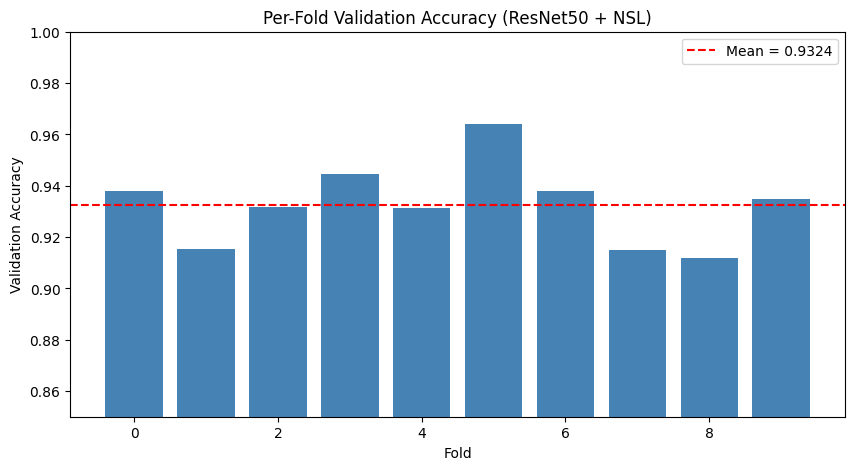


✅ Step 7 complete.


In [13]:
# ============================================================
# STEP 7: Aggregate fold metrics
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

with open(RESULTS_PATH, "r") as f:
    fold_results = json.load(f)

val_accs = [fold_results[str(i)]["best_val_accuracy"] for i in range(N_FOLDS)]
mean_acc, std_acc = np.mean(val_accs), np.std(val_accs)

print("Per-fold best validation accuracy:")
for i, acc in enumerate(val_accs):
    print(f"  Fold {i}: {acc:.4f}")
print(f"\nMean CV accuracy: {mean_acc:.4f} ± {std_acc:.4f}")
print(f"Min: {min(val_accs):.4f} (fold {np.argmin(val_accs)})  |  Max: {max(val_accs):.4f} (fold {np.argmax(val_accs)})")

plt.figure(figsize=(10, 5))
plt.bar(range(N_FOLDS), val_accs, color='steelblue')
plt.axhline(mean_acc, color='red', linestyle='--', label=f'Mean = {mean_acc:.4f}')
plt.xlabel("Fold"); plt.ylabel("Validation Accuracy")
plt.title("Per-Fold Validation Accuracy (ResNet50 + NSL)")
plt.ylim(0.85, 1.0)
plt.legend()
plt.savefig("/kaggle/working/fold_accuracy_bar.png", dpi=100)
plt.show()

print("\n✅ Step 7 complete.")

In [16]:
# ---- FIX: build the wrapper model before loading weights ----
def tta_predict(model, X_batch):
    views = [
        X_batch,
        tf.image.flip_left_right(X_batch),
        tf.image.adjust_brightness(X_batch, delta=5.0),
        tf.image.adjust_brightness(X_batch, delta=-5.0),
    ]
    all_probs = []
    for v in views:
        logits, _ = model(v, training=False)
        all_probs.append(tf.nn.softmax(tf.cast(logits, tf.float32), axis=-1))
    return tf.reduce_mean(tf.stack(all_probs, axis=0), axis=0)

N_CLASSES = 3
oof_probs = np.zeros((len(y_encoded), N_CLASSES), dtype=np.float32)
oof_filled = np.zeros(len(y_encoded), dtype=bool)

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")
    print(f"Fold {fold_i}: predicting on {len(val_idx)} held-out samples...")

    with strategy.scope():
        backbone, _ = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(base_model=backbone, global_batch_size=BATCH_SIZE)
        dummy_input = tf.zeros((1, 224, 224, 3), dtype=tf.float32)
        _ = nsl_model(dummy_input, training=False)   # builds the wrapper

    nsl_model.load_weights(ckpt_path)

    X_val = X_preprocessed[val_idx]
    fold_probs = []
    for start in range(0, len(X_val), BATCH_SIZE):
        batch = X_val[start:start + BATCH_SIZE]
        fold_probs.append(tta_predict(nsl_model, batch).numpy())
    fold_probs = np.concatenate(fold_probs, axis=0)

    oof_probs[val_idx] = fold_probs
    oof_filled[val_idx] = True

    del nsl_model, backbone
    tf.keras.backend.clear_session()

assert oof_filled.all(), "Some samples never got predicted - check fold_indices coverage!"
oof_preds = np.argmax(oof_probs, axis=1)

np.save("/kaggle/working/oof_probs.npy", oof_probs)
np.save("/kaggle/working/oof_preds.npy", oof_preds)

oof_accuracy = (oof_preds == y_encoded).mean()
print(f"\nOverall OOF accuracy (TTA, leakage-free, full 3064-image dataset): {oof_accuracy:.4f}")
print("\n✅ Step 8 complete.")

Fold 0: predicting on 307 held-out samples...
Fold 1: predicting on 307 held-out samples...
Fold 2: predicting on 307 held-out samples...
Fold 3: predicting on 307 held-out samples...
Fold 4: predicting on 306 held-out samples...
Fold 5: predicting on 306 held-out samples...
Fold 6: predicting on 306 held-out samples...
Fold 7: predicting on 306 held-out samples...
Fold 8: predicting on 306 held-out samples...
Fold 9: predicting on 306 held-out samples...

Overall OOF accuracy (TTA, leakage-free, full 3064-image dataset): 0.9324

✅ Step 8 complete.


Classification Report (Out-of-Fold, TTA):

              precision    recall  f1-score   support

  meningioma     0.9740    0.7938    0.8747       708
      glioma     0.9415    0.9600    0.9507      1426
   pituitary     0.8964    0.9957    0.9435       930

    accuracy                         0.9324      3064
   macro avg     0.9373    0.9165    0.9230      3064
weighted avg     0.9353    0.9324    0.9309      3064



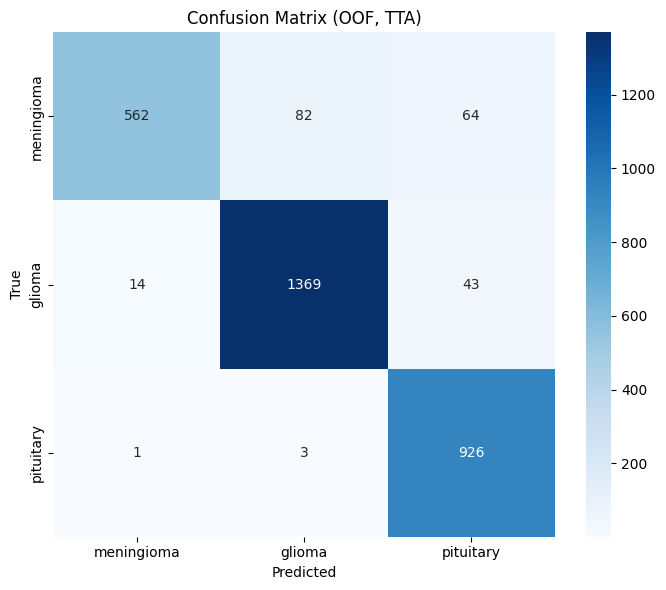

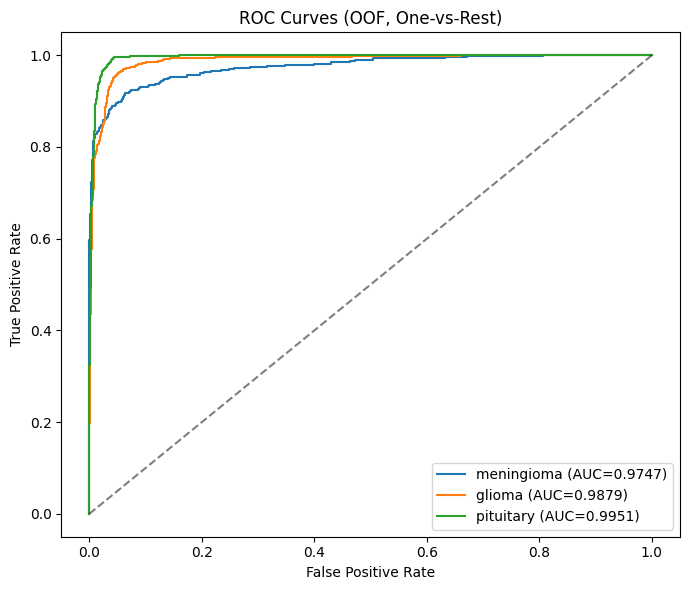

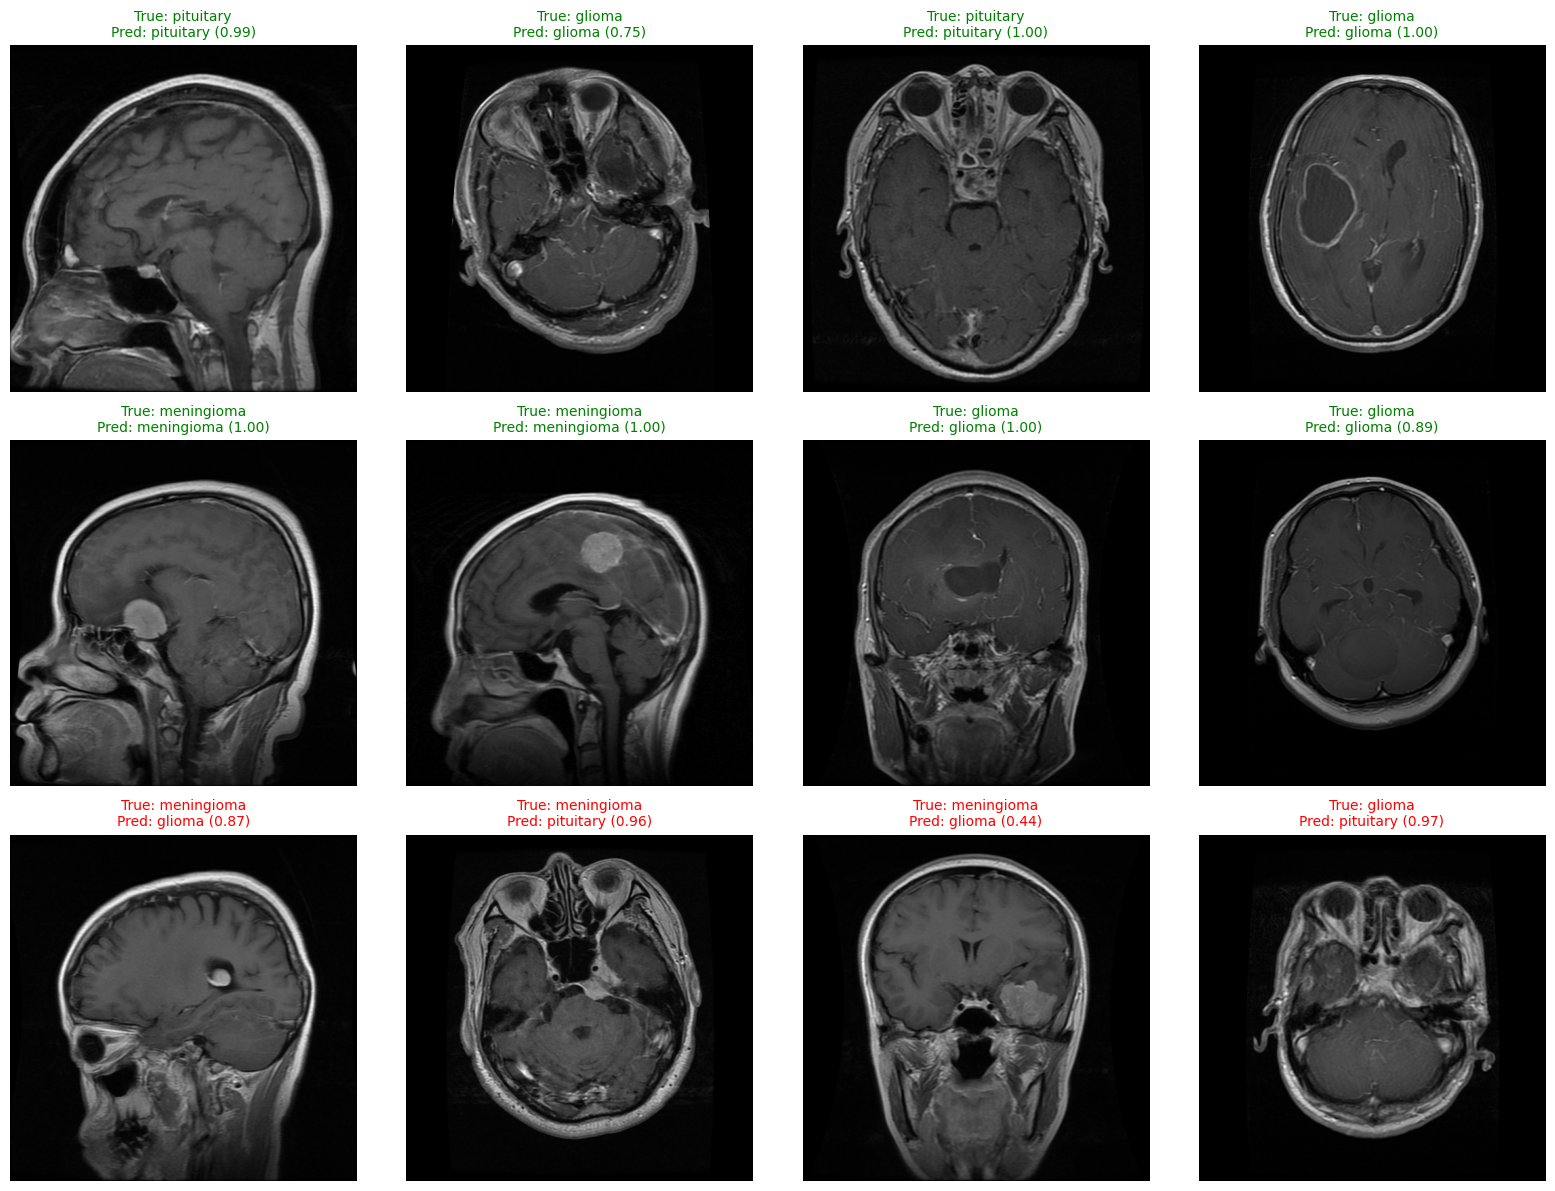


✅ Step 9 complete.
Final OOF accuracy (10-fold ensemble, TTA): 0.9324
All deliverables zipped: /kaggle/working/figshare_resnet_nsl_final.zip


In [17]:
# ============================================================
# STEP 9: Final evaluation + save deliverables
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns
import shutil

CLASS_NAMES = ["meningioma", "glioma", "pituitary"]

# ---- Classification report ----
report = classification_report(y_encoded, oof_preds, target_names=CLASS_NAMES, digits=4)
print("Classification Report (Out-of-Fold, TTA):\n")
print(report)
with open("/kaggle/working/classification_report.txt", "w") as f:
    f.write(report)

# ---- Confusion matrix ----
cm = confusion_matrix(y_encoded, oof_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (OOF, TTA)")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=120)
plt.show()

# ---- ROC curves (multi-class, one-vs-rest) ----
y_bin = label_binarize(y_encoded, classes=[0, 1, 2])
plt.figure(figsize=(7, 6))
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], oof_probs[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves (OOF, One-vs-Rest)"); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("/kaggle/working/roc_curves.png", dpi=120)
plt.show()

# ---- Sample prediction grid (correct + incorrect) ----
correct_idx = np.where(oof_preds == y_encoded)[0]
incorrect_idx = np.where(oof_preds != y_encoded)[0]
sample_correct = np.random.choice(correct_idx, 8, replace=False)
sample_incorrect = np.random.choice(incorrect_idx, min(4, len(incorrect_idx)), replace=False) if len(incorrect_idx) > 0 else []
sample_idxs = list(sample_correct) + list(sample_incorrect)

n_cols = 4
n_rows = int(np.ceil(len(sample_idxs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()
for ax, idx in zip(axes, sample_idxs):
    ax.imshow(images[idx], cmap='gray')
    true_name, pred_name = CLASS_NAMES[y_encoded[idx]], CLASS_NAMES[oof_preds[idx]]
    conf = oof_probs[idx, oof_preds[idx]]
    color = 'green' if y_encoded[idx] == oof_preds[idx] else 'red'
    ax.set_title(f"True: {true_name}\nPred: {pred_name} ({conf:.2f})", color=color, fontsize=10)
    ax.axis('off')
for ax in axes[len(sample_idxs):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig("/kaggle/working/prediction_samples.png", dpi=120)
plt.show()

# ---- Package everything ----
FINAL_DIR = "/kaggle/working/final_model_package"
os.makedirs(FINAL_DIR, exist_ok=True)
for fold_i in range(N_FOLDS):
    src = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")
    if os.path.exists(src):
        shutil.copy(src, FINAL_DIR)
for fname in ["classification_report.txt", "confusion_matrix.png", "roc_curves.png",
              "prediction_samples.png", "fold_accuracy_bar.png"]:
    fpath = f"/kaggle/working/{fname}"
    if os.path.exists(fpath):
        shutil.copy(fpath, FINAL_DIR)
shutil.copy(RESULTS_PATH, FINAL_DIR)
np.save(os.path.join(FINAL_DIR, "oof_probs.npy"), oof_probs)
np.save(os.path.join(FINAL_DIR, "oof_preds.npy"), oof_preds)
shutil.make_archive("/kaggle/working/figshare_resnet_nsl_final", 'zip', FINAL_DIR)

print(f"\n✅ Step 9 complete.")
print(f"Final OOF accuracy (10-fold ensemble, TTA): {oof_accuracy:.4f}")
print("All deliverables zipped: /kaggle/working/figshare_resnet_nsl_final.zip")